# 59. Full-range 6D Rotation Flow Matching (KAIST)

This notebook adapts the **physical augmentation, one-sensor faults, angular probes, stochastic preflight, full training, and matched chronological rollouts** from Notebook 58, but replaces its direct regression head with **10D Euclidean Flow Matching**.

- Rotation is represented by two columns of the *correction* matrix, 6D. Translation and tau are additive, 3D + 1D.
- The flow starts at the identity 6D rotation embedding and ends at the full GT correction. No bounded teacher or principal SO(3) logarithm appears in the FM path.
- Intermediate 6D coordinates are not projected to SO(3); the final endpoint is orthogonalized before application.
- Analytic correction-to-go velocity loss plus **differentiably integrated full-GT endpoint loss**.
- The pretrained **Notebook 57 6D regression feature extractor** initializes the Transformer/pooler/MLP; the velocity head is new.
- Stochastic preflight and full training report fixed 0/30/60/90/120/150/175/179° probes. Full training stays **off** until preflight inspection.
- Appendix: matched 12-window rollouts, baseline trained 6D regression vs 6D FM, 64 cases/angle by default.

**Dependency:** install the 5 new modules and the existing 6D regression modules. This also uses the optional minimum uniform angle augmentation from Notebook 58.


## 1. Imports and new 6D Flow Matching modules


In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run from the nn-obs-calib repository or a descendant directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.rotation_6d import matrix_to_rotation_6d, rotation_6d_to_matrix
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
from obscalib.calibration.rotation_6d_update import apply_calibration_6d_update
from obscalib.training.rotation_6d_loss import Calibration6DLossWeights
from obscalib.models.pooled_calibration_flow_6d_model import PooledCalibrationFlow6DModel
from obscalib.flow_matching.rotation_6d_path import identity_6d_flow_state, stack_rotation_6d_flow_target, make_rotation_6d_flow_batch
from obscalib.flow_matching.rotation_6d_integrator import integrate_rotation_6d_flow
from obscalib.training.rotation_6d_flow_loss import Rotation6DFlowLossWeights, rotation_6d_targets_from_calibration, rotation_6d_flow_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())


Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126 | CUDA: True


## 2. Experiment: full-range 6D FM with mixed fine/coarse faults


In [2]:
RUN_NAME = 'kaist_pooled_calibration_fm_6d.1_full_range'
RUN_DIR = ROOT / 'runs' / RUN_NAME
BASELINE_6D_RUN_NAME = 'kaist_pooled_calibration_6d_002.27_full_rotation_regression'
BASELINE_6D_CHECKPOINT = ROOT / 'runs' / BASELINE_6D_RUN_NAME / 'best.pt'
# Always initialize the complete 6D model from its trained predecessor, not a new head.
INIT_6D_CHECKPOINT = BASELINE_6D_CHECKPOINT

RANDOM_SEED, TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 12345, 23456, 34567, 45678
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE, NUM_WORKERS, GRADIENT_ACCUMULATION_STEPS = 16, 0, 1
NUM_EPOCHS, WEIGHT_DECAY, GRADIENT_CLIP_NORM = 100, 1e-4, 1.0
HEAD_MLP_LR = 3e-4
TRANSFORMER_LR = HEAD_MLP_LR / 10.0
LR_REDUCE_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10
RUN_FULL_TRAINING = True
RESUME_FULL_TRAINING = False
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0

# Original notebook 47 tau references (all three physical sensor streams remain present).
REFINED_TAU_BY_SENSOR_S = {'imu': 0.0, 'lidar': -0.025, 'lidar_right': -0.035}
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_CALIBRATION_TIME_OFFSET_MAX_S = 0.030

# Fine prior distribution retains Notebook 47's Student-t rotation/timing model.
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
# Coarse faults are deliberately broad, not Student-t tails that almost never visit 175–179°.
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 60.0, 179.0
COARSE_PRIOR_PROBABILITY = 0.50
PRIOR_TRANSLATION_MAX_M, PRIOR_TRANSLATION_SCALE_M = 0.05, 0.02
PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.50, 0.25
STUDENT_T_DOF = 3
# Small analytic velocity loss, stronger full-GT endpoint supervision.
FLOW_LOSS_WEIGHTS = Rotation6DFlowLossWeights(
    velocity_weight=0.1, endpoint_weight=1.0,
    velocity_rotation_6d_scale=1.0, velocity_translation_scale_m=0.1, velocity_time_offset_scale_s=0.25,
    endpoint=Calibration6DLossWeights(rotation_weight=2.0, rotation_6d_weight=1.0, rotation_chordal_weight=1.0, translation_weight=1.0, time_offset_weight=1.0, translation_scale_m=0.05, time_offset_scale_s=0.05),
)
ACTIVE_ROTATION_SUPERVISION_WEIGHT = 0.25
TRAIN_INTEGRATION_STEPS, TRAIN_INTEGRATION_METHOD = 4, 'euler'
FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD = 8, 'midpoint'
STOCHASTIC_EVAL_INTEGRATION_STEPS = 8
FLOW_MODE = 'mixed'
FLOW_OFF_PATH_PROBABILITY, FLOW_IDENTITY_PROBABILITY = 0.40, 0.15
FLOW_MAX_TIME = 0.95
FLOW_ROTATION_NOISE_STD = 0.10  # Per 6D embedding coordinate, NOT radians.
FLOW_TRANSLATION_NOISE_STD_M, FLOW_TAU_NOISE_STD_S = 0.02, 0.02

# Fixed validation probe: model-selected checkpoint must work at coarse angles, not only lower val loss.
PROBE_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
PROBE_FINE_SCORE_ANGLES_DEG = (30.0, 60.0, 90.0)
PROBE_COARSE_SCORE_ANGLES_DEG = (120.0, 150.0, 175.0, 179.0)
PROBE_SCORE_ANGLES_DEG = PROBE_FINE_SCORE_ANGLES_DEG + PROBE_COARSE_SCORE_ANGLES_DEG
PROBE_COARSE_SCORE_WEIGHT = 0.50
PROBE_WINDOWS, PROBE_BATCH_SIZE, PROBE_AXIS_SEEDS = 32, 8, 2
PROBE_FAULT_KEYS = ('lidar', 'lidar_right')
PROBE_EVERY_EPOCHS = 1
ZERO_DRIFT_WEIGHT = 0.15  # penalty in relative-score units: zero-angle drift / 30°
SHOW_PLOTS = True

KAIST_TAU_IMU_S = 0.0
KAIST_TAU_LIDAR_S = -0.025
KAIST_TAU_LIDAR_RIGHT_S = -0.035
REFINED_TAU_BY_SENSOR_S = {"imu": KAIST_TAU_IMU_S, "lidar": KAIST_TAU_LIDAR_S, "lidar_right": KAIST_TAU_LIDAR_RIGHT_S}
assert abs((KAIST_TAU_LIDAR_S - KAIST_TAU_IMU_S) * 1000 + 25.0) < 1e-8
assert abs((KAIST_TAU_LIDAR_RIGHT_S - KAIST_TAU_IMU_S) * 1000 + 35.0) < 1e-8

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

# Test data are kept untouched until consciously enabling final evaluation.
RUN_FINAL_TEST_EVALUATION = True

assert abs(TRANSFORMER_LR * 10.0 - HEAD_MLP_LR) < 1e-12
assert 0.0 < COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180.0
assert 0 <= COARSE_PRIOR_PROBABILITY <= 1
assert set(PROBE_FAULT_KEYS).issubset(CALIBRATION_KEYS)
if not INIT_6D_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Fully trained 6D initialization checkpoint not found: {INIT_6D_CHECKPOINT}')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Run:', RUN_DIR)
print('Learning rates: head/MLP/pooler=', HEAD_MLP_LR, '| Transformer=', TRANSFORMER_LR)
print('Single topology:', CALIBRATION_KEYS, '| no topology or artificial sensor-noise augmentation')

print('Coarse prior:', COARSE_PRIOR_PROBABILITY, 'of examples with rotation magnitude in', (COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), 'degrees')
print('Feature warm start:', INIT_6D_CHECKPOINT, '| new 6D FM velocity head, full training enabled:', RUN_FULL_TRAINING)


Run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_6d.1_full_range
Learning rates: head/MLP/pooler= 0.0003 | Transformer= 2.9999999999999997e-05
Single topology: ('imu', 'lidar', 'lidar_right') | no topology or artificial sensor-noise augmentation
Coarse prior: 0.5 of examples with rotation magnitude in (60.0, 179.0) degrees
Feature warm start: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt | new 6D FM velocity head, full training enabled: True


## 3. KAIST data, splits and corrected timing reference (from Notebook 47)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)
print("Corrected rig τ [ms]:", {key: 1000.0 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']
Corrected rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

# Check the actual WindowBatch ground truth, not just constructor arguments.
for split_name, split_dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    sample = collate_windows([split_dataset[0]])
    for sensor, expected_s in REFINED_TAU_BY_SENSOR_S.items():
        observed = float(sample.current_calibration[sensor].time_offset.reshape(-1)[0].item())
        assert abs(observed - expected_s) < 2e-6, f"{split_name}/{sensor}: dataset τ={observed} but expected {expected_s}"
    print(f"{split_name}: τ targets [ms] verified:", {sensor: round(float(state.time_offset.reshape(-1)[0]) * 1000, 3) for sensor, state in sample.current_calibration.items()})

# Compare the zero-clock and corrected-clock dataset instances on the same held-out
# physical windows. This checks whether the loader alters raw measurements when the
# rig reference changes; it never deliberately shifts raw timestamps in this notebook.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
zero_clock_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], zero_clock_rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
corrected_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
if len(zero_clock_control) != len(corrected_control):
    raise RuntimeError("Changing calibration τ modified the number of windows. Inspect dataset timestamp processing before training.")
for index in sorted({0, len(zero_clock_control)//2, len(zero_clock_control)-1}):
    old, new = zero_clock_control[index], corrected_control[index]
    for stream_name in old.streams:
        old_stream, new_stream = old.streams[stream_name], new.streams[stream_name]
        torch.testing.assert_close(old_stream.values, new_stream.values, rtol=0, atol=0)
        torch.testing.assert_close(old_stream.timestamps, new_stream.timestamps, rtol=0, atol=0)
        if old_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(old_stream.interval_start_timestamps, new_stream.interval_start_timestamps, rtol=0, atol=0)
print("PASS: refined τ changes calibration reference while preserving native stream measurements and timestamps.")
del zero_clock_control, corrected_control


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Same physically consistent true-calibration augmentation and mixed independent faults (no topology augmentation)


In [6]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD), time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TIME_OFFSET_MAX_S)),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(true_calibration_config)

def prior_config(rotation_max_rad, rotation_distribution, rotation_scale_rad=None, *, rotation_min_rad=0.0):
    rotation_kwargs = dict(maximum=rotation_max_rad, minimum=rotation_min_rad, distribution=rotation_distribution)
    if rotation_distribution == PerturbationDistribution.TRUNCATED_STUDENT_T:
        rotation_kwargs.update(scale=rotation_scale_rad, degrees_of_freedom=STUDENT_T_DOF)
    return PriorPerturbationConfig(
        enabled=True, probability=1.0,
        rotation=PerturbationMagnitudeConfig(**rotation_kwargs),
        translation=PerturbationMagnitudeConfig(maximum=PRIOR_TRANSLATION_MAX_M, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TRANSLATION_SCALE_M, degrees_of_freedom=STUDENT_T_DOF),
        time_offset=PerturbationMagnitudeConfig(maximum=PRIOR_TAU_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TAU_SCALE_S, degrees_of_freedom=STUDENT_T_DOF),
        one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
    )

fine_prior_config = prior_config(np.deg2rad(FINE_ROTATION_MAX_DEG), PerturbationDistribution.TRUNCATED_STUDENT_T, np.deg2rad(FINE_ROTATION_SCALE_DEG))
coarse_prior_config = prior_config(np.deg2rad(COARSE_ROTATION_MAX_DEG), PerturbationDistribution.UNIFORM, rotation_min_rad=np.deg2rad(COARSE_ROTATION_MIN_DEG))
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)


def augmentation_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def clone_with_current_calibration(window, states):
    return WindowBatch(streams=dict(window.streams), current_calibration=states, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)


def apply_independent_prior_faults(states, xi_by_key, tau_by_key):
    """Left-rotate only R; add independent parent-frame t and tau faults. Never rotate t with R."""
    updated = {}
    for key, state in states.items():
        xi = xi_by_key[key]
        prior = state.transform.clone()
        prior[:, :3, :3] = so3_exp(xi[:, :3]) @ state.transform[:, :3, :3]
        prior[:, :3, 3] = state.transform[:, :3, 3] + xi[:, 3:]
        updated[key] = replace(state, transform=prior, time_offset=state.time_offset + tau_by_key[key])
    return updated


@torch.no_grad()
def make_training_window(base_window, *, generator):
    """Physical augmentation followed by exactly one sensor's fine or coarse prior fault."""
    physical = physical_augmenter(base_window, generator=generator).augmented_window
    true_states = physical.current_calibration
    _, fine_xi, fine_tau = fine_prior_perturber(true_states, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(true_states, generator=generator)
    batch_size = next(iter(true_states.values())).transform.shape[0]
    coarse_mask = torch.rand(batch_size, device=DEVICE, generator=generator) < COARSE_PRIOR_PROBABILITY
    # Coarse magnitudes are sampled directly from the configured [60°, 179°]
    # interval by the shared sampler. Do NOT rescale or re-sample coarse angles here.
    xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in true_states}
    tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in true_states}
    return clone_with_current_calibration(physical, apply_independent_prior_faults(true_states, xi, tau))


assert tuple(CALIBRATION_KEYS) == ('imu', 'lidar', 'lidar_right')
assert not true_calibration_config.sensor_topology.enabled
assert not true_calibration_config.frame_randomization.enabled
assert not true_calibration_config.common_body_frame.enabled
assert not true_calibration_config.noise.enabled
print('True-calibration re-expression enabled; topology/noise/frame augmentation disabled.')
print('Fine prior:', fine_prior_config)
print('Coarse prior:', coarse_prior_config)

# Distribution smoke test. This samples rotation magnitudes directly, without applying sensor masks.
from obscalib.augmentations.sampling import sample_perturbation_magnitudes
sampling_probe = sample_perturbation_magnitudes(coarse_prior_config.rotation, 4096, device=DEVICE, dtype=DTYPE, generator=augmentation_generator(TRAIN_AUG_SEED + 41414))
sampled_angles_deg = torch.rad2deg(sampling_probe).squeeze(-1)
assert bool((sampled_angles_deg >= COARSE_ROTATION_MIN_DEG - 1e-4).all())
assert bool((sampled_angles_deg <= COARSE_ROTATION_MAX_DEG + 1e-4).all())
assert coarse_prior_config.rotation.minimum > 0.0
print(f'Coarse sampler verified: {sampled_angles_deg.min().item():.3f}° to {sampled_angles_deg.max().item():.3f}° over 4096 draws')


True-calibration re-expression enabled; topology/noise/frame augmentation disabled.
Fine prior: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.5235987755982988, degrees_of_freedom=3, minimum=0.0), translation=PerturbationMagnitudeConfig(maximum=0.05, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.02, degrees_of_freedom=3, minimum=0.0), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.25, degrees_of_freedom=3, minimum=0.0), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False)
Coarse prior: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximu

## 5. Pretrained 6D sensor features + NEW 10D FM velocity head


In [7]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)

source_6d = PooledCalibration6DModel(model_config).to(device='cpu', dtype=DTYPE)
load_training_checkpoint(INIT_6D_CHECKPOINT, model=source_6d, map_location='cpu', restore_rng_state=False)
model = PooledCalibrationFlow6DModel(model_config, integration_steps=FM_INTEGRATION_STEPS, integration_method=FM_INTEGRATION_METHOD).to(device=DEVICE, dtype=DTYPE)
model.initialize_backbone_from_regression(source_6d, freeze=False)
del source_6d
model.head_6d_flow.requires_grad_(True)
assert all(p.requires_grad for p in model.parameters())


def tokenize_window(window):
    """Canonical GeometryProcessor+Tokenizer; no legacy SE(3) WindowStep."""
    if tuple(window.current_calibration) != CALIBRATION_KEYS:
        raise ValueError(f'Unexpected topology/order: {tuple(window.current_calibration)}')
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    return tokenizer(streams, calibration_keys=tuple(window.current_calibration))


def model_predictions(window, *, model_override=None):
    """Both the original 6D regressor and the new FM produce 6D predictions."""
    used_model = model if model_override is None else model_override
    tokens = tokenize_window(window)
    if isinstance(used_model, PooledCalibrationFlow6DModel):
        return used_model(tokens, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    return used_model(tokens)


def parameter_groups(module):
    transformer = list(module.transformer_encoder.parameters())
    other = list(module.pooler.parameters()) + list(module.mlp_body.parameters()) + list(module.head_6d_flow.parameters())
    if len({id(p) for p in transformer + other}) != len(transformer + other):
        raise RuntimeError('Overlapping optimizer groups')
    if len(transformer + other) != len(list(module.parameters())):
        raise RuntimeError('Optimizer groups miss model parameters')
    return [dict(params=transformer, lr=TRANSFORMER_LR, name='transformer'), dict(params=other, lr=HEAD_MLP_LR, name='pooler_mlp_fm_head')]


optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_EPOCHS)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))
print('LRs:', [(group['name'], group['lr']) for group in optimizer.param_groups])
print('FM integrates', FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD, 'steps at inference; no conversion through SE3 Log')


Trainable parameters: 2555978
LRs: [('transformer', 2.9999999999999997e-05), ('pooler_mlp_fm_head', 0.0003)]
FM integrates 8 midpoint steps at inference; no conversion through SE3 Log


## 6. Velocity and integrated endpoint objective (full GT, 6D rotation)


In [8]:
def rotation_geodesic_deg(R_first, R_second):
    """Numerically stable SO(3) distance, including near 180°."""
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))


def compute_fm_objective(window, *, generator):
    """One Transformer encode, analytic CTG query, differentiable integrated endpoint."""
    if window.targets is None:
        raise ValueError('Full GT targets required for FM training')
    rotations, translations, clocks = rotation_6d_targets_from_calibration(window.current_calibration, window.targets)
    tokens = tokenize_window(window)
    fm_output = model.forward_flow_matching(tokens, rotations, translations, clocks, mode=FLOW_MODE, off_path_probability=FLOW_OFF_PATH_PROBABILITY, identity_probability=FLOW_IDENTITY_PROBABILITY, rotation_noise_std=FLOW_ROTATION_NOISE_STD, translation_noise_std_m=FLOW_TRANSLATION_NOISE_STD_M, tau_noise_std_s=FLOW_TAU_NOISE_STD_S, max_time=FLOW_MAX_TIME, generator=generator, shared_across_calibrations=True)
    integrated = model.integrate_from_features(fm_output.shared_features, fm_output.stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    predictions = model.predictions_from_result(integrated, fm_output.calibration_keys)
    losses = rotation_6d_flow_loss(fm_output.predicted_velocity, fm_output.flow_batch.target_velocity, endpoint_predictions=predictions, current_calibration=window.current_calibration, targets=window.targets, weights=FLOW_LOSS_WEIGHTS)

    # Preserve an explicit active-fault endpoint term; healthy-sensor identity is
    # still supervised by the full endpoint loss for every calibration key.
    active_terms, errors = [], []
    for key in CALIBRATION_KEYS:
        prior, target, prediction = window.current_calibration[key], window.targets[key], predictions[key]
        rotation_target = target.next_transform[:, :3, :3] @ prior.transform[:, :3, :3].transpose(-1, -2)
        angle_before = rotation_geodesic_deg(prior.transform[:, :3, :3], target.next_transform[:, :3, :3])
        active = angle_before > 1e-3
        if bool(active.any()):
            reg = (prediction.rotation_6d - rotations[key]).square().mean(dim=-1)
            chord = 0.5 * (prediction.delta_rotation - rotation_target).square().sum(dim=(-2, -1))
            active_terms.append((FLOW_LOSS_WEIGHTS.endpoint.rotation_6d_weight * reg + FLOW_LOSS_WEIGHTS.endpoint.rotation_chordal_weight * chord)[active])
            errors.append(rotation_geodesic_deg(prediction.delta_rotation[active], rotation_target[active]).detach())
    extra_active = FLOW_LOSS_WEIGHTS.endpoint.rotation_weight * torch.cat(active_terms).mean() if active_terms else losses.total * 0.0
    loss = losses.total + ACTIVE_ROTATION_SUPERVISION_WEIGHT * extra_active
    with torch.no_grad():
        metrics = dict(loss_total=float(loss.detach()), loss_velocity=float(losses.velocity.detach()), loss_endpoint=float(losses.endpoint.detach()), loss_rotation_6d=float(losses.endpoint_rotation.detach()), loss_translation=float(losses.endpoint_translation.detach()), loss_tau=float(losses.endpoint_time_offset.detach()), loss_active_rotation=float(extra_active.detach()), active_rotation_error_deg=float(torch.cat(errors).mean()) if errors else 0.0, active_rotation_count=sum(x.numel() for x in errors))
    return loss, metrics


def metric_average(sums, counts):
    return {key: sums[key] / counts[key] for key in sums}


## 7. Geometry, 179° velocity and endpoint-gradient smoke tests


In [9]:
# Verify the *analytic* 6D flow and gradients before any optimizer steps.
probe_R = so3_exp(torch.tensor([[np.deg2rad(179.0), 0.0, 0.0]], dtype=DTYPE, device=DEVICE))
probe_target = stack_rotation_6d_flow_target(matrix_to_rotation_6d(probe_R), torch.zeros(1, 3, dtype=DTYPE, device=DEVICE), torch.zeros(1, 1, dtype=DTYPE, device=DEVICE))
flow_smoke = make_rotation_6d_flow_batch(probe_target, time=torch.full((1, 1), 0.5, device=DEVICE, dtype=DTYPE), mode='on_path')
torch.testing.assert_close(flow_smoke.state + 0.5 * flow_smoke.target_velocity, probe_target)

smoke_base = window_batch_to(collate_windows([train_dataset[0], train_dataset[min(100, len(train_dataset) - 1)]]), DEVICE, dtype=DTYPE)
smoke_window = make_training_window(smoke_base, generator=augmentation_generator(TRAIN_AUG_SEED + 101))
assert tuple(smoke_window.current_calibration) == CALIBRATION_KEYS
for key in CALIBRATION_KEYS:
    target = smoke_window.targets[key]
    assert target.next_transform is not None and target.next_time_offset is not None
    R = smoke_window.current_calibration[key].transform[:, :3, :3]
    R_gt = target.next_transform[:, :3, :3]
    R_delta = R_gt @ R.transpose(-1, -2)
    torch.testing.assert_close(rotation_6d_to_matrix(matrix_to_rotation_6d(R_delta)), R_delta, atol=5e-5, rtol=5e-5)
model.train()
optimizer.zero_grad(set_to_none=True)
smoke_loss, smoke_metrics = compute_fm_objective(smoke_window, generator=augmentation_generator(TRAIN_AUG_SEED + 1001))
smoke_loss.backward()
for name in ('transformer_encoder', 'pooler', 'mlp_body', 'head_6d_flow'):
    grads = [p.grad for p in getattr(model, name).parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(bool(torch.isfinite(g).all()) for g in grads), f'{name}: missing/nonfinite gradients'
    print(name, 'gradient norm:', round(math.sqrt(sum(float(g.square().sum()) for g in grads)), 5))
assert torch.isfinite(smoke_loss) and smoke_metrics['active_rotation_count'] > 0
optimizer.zero_grad(set_to_none=True)
model.eval()
print('PASS: 6D FM CTG and integrated endpoint backpropagate to all unfrozen layers.')
print('Smoke velocity / endpoint:', smoke_metrics['loss_velocity'], smoke_metrics['loss_endpoint'])
del smoke_base, smoke_window, smoke_loss


transformer_encoder gradient norm: 2.31373
pooler gradient norm: 0.60187
mlp_body gradient norm: 0.99427
head_6d_flow gradient norm: 22.79899
PASS: 6D FM CTG and integrated endpoint backpropagate to all unfrozen layers.
Smoke velocity / endpoint: 0.04925018548965454 3.527125358581543


## 8. Fixed held-out angular probes: identical physical windows and faults


In [10]:
@torch.no_grad()
def build_probe_batches(dataset, *, n_windows, batch_size, seed, angles=PROBE_ANGLES_DEG, axis_seeds=PROBE_AXIS_SEEDS):
    indices = np.unique(np.linspace(0, len(dataset) - 1, min(len(dataset), n_windows)).round().astype(int))
    batches = []
    for axis_seed in range(axis_seeds):
        for group_id, start in enumerate(range(0, len(indices), batch_size)):
            chosen = indices[start:start + batch_size]
            base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
            generator = augmentation_generator(seed + axis_seed * 100003 + group_id * 1009)
            physical = physical_augmenter(base, generator=generator).augmented_window
            n = len(chosen)
            template = next(iter(physical.current_calibration.values())).transform
            axes = torch.randn(n, 3, generator=generator, device=template.device, dtype=template.dtype)
            axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-9)
            cases = {}
            for angle in angles:
                xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                tau = {key: torch.zeros(n, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                keys = [PROBE_FAULT_KEYS[(j + axis_seed) % len(PROBE_FAULT_KEYS)] for j in range(n)]
                for j, key in enumerate(keys):
                    xi[key][j, :3] = axes[j] * np.deg2rad(float(angle))
                prior = apply_independent_prior_faults(physical.current_calibration, xi, tau)
                cases[float(angle)] = (clone_with_current_calibration(physical, prior), keys, chosen.copy(), axis_seed)
            batches.append(cases)
    return batches


@torch.inference_mode()
def evaluate_probe(model_to_evaluate, batches):
    original_training = model_to_evaluate.training
    model_to_evaluate.eval()
    rows = []
    try:
        for cases in batches:
            for angle, (window, fault_keys, indices, axis_seed) in cases.items():
                output = model_predictions(window, model_override=model_to_evaluate)
                updated = apply_calibration_6d_update(window.current_calibration, output.predictions)
                for j, active_key in enumerate(fault_keys):
                    pred_state, truth = updated[active_key], window.targets[active_key]
                    before = rotation_geodesic_deg(window.current_calibration[active_key].transform[j:j+1, :3, :3], truth.next_transform[j:j+1, :3, :3]).item()
                    after = rotation_geodesic_deg(pred_state.transform[j:j+1, :3, :3], truth.next_transform[j:j+1, :3, :3]).item()
                    step = rotation_geodesic_deg(output.predictions[active_key].delta_rotation[j:j+1], torch.eye(3, device=DEVICE, dtype=DTYPE).reshape(1, 3, 3)).item()
                    target_R = truth.next_transform[j:j+1, :3, :3] @ window.current_calibration[active_key].transform[j:j+1, :3, :3].transpose(-1, -2)
                    # Only a diagnostic. Geodesic error determines success, not signed axis agreement.
                    target_6d = matrix_to_rotation_6d(target_R)
                    embedded_error = (output.predictions[active_key].rotation_6d[j:j+1] - target_6d).square().mean().item()
                    healthy = [k for k in CALIBRATION_KEYS if k != active_key]
                    healthy_drift = np.mean([rotation_geodesic_deg(updated[k].transform[j:j+1, :3, :3], window.targets[k].next_transform[j:j+1, :3, :3]).item() for k in healthy])
                    rows.append(dict(angle_deg=float(angle), physical_index=int(indices[j]), axis_seed=axis_seed, fault_key=active_key, before_deg=before, after_deg=after, improvement_deg=before-after, relative_remaining=after/max(before, 1e-6) if before > 1e-4 else np.nan, step_deg=step, error_6d=embedded_error, healthy_drift_deg=healthy_drift, improved=after < before - 1e-5))
    finally:
        model_to_evaluate.train(original_training)
    return pd.DataFrame(rows)


def summarize_probe(frame):
    return frame.groupby('angle_deg', as_index=False).agg(n=('after_deg', 'size'), before_deg=('before_deg', 'mean'), final_deg=('after_deg', 'mean'), improvement_deg=('improvement_deg', 'mean'), relative_remaining=('relative_remaining', 'mean'), fraction_improving=('improved', 'mean'), predicted_step_deg=('step_deg', 'mean'), healthy_drift_deg=('healthy_drift_deg', 'mean'), error_6d=('error_6d', 'mean'))


def probe_score(summary):
    """Prioritize recovery at 60–179°, while penalizing fine-angle regression and zero-state drift."""
    fine = summary[summary.angle_deg.isin(PROBE_FINE_SCORE_ANGLES_DEG)]
    coarse = summary[summary.angle_deg.isin(PROBE_COARSE_SCORE_ANGLES_DEG)]
    if len(fine) != len(PROBE_FINE_SCORE_ANGLES_DEG) or len(coarse) != len(PROBE_COARSE_SCORE_ANGLES_DEG):
        raise ValueError('Fixed probe has missing required fine/coarse angles')
    zero = summary.loc[np.isclose(summary.angle_deg, 0.0), 'final_deg']
    zero_drift = float(zero.mean()) if len(zero) else 0.0
    score = PROBE_COARSE_SCORE_WEIGHT * float(coarse.relative_remaining.mean()) + (1.0 - PROBE_COARSE_SCORE_WEIGHT) * float(fine.relative_remaining.mean())
    return score + ZERO_DRIFT_WEIGHT * zero_drift / 30.0


def print_probe_summary(frame, *, label):
    summary = summarize_probe(frame)
    print(label, '| normalized residual score:', f'{probe_score(summary):.4f}', '| lower is better')
    display(summary.round(3))
    return summary


full_probe_batches = build_probe_batches(val_dataset, n_windows=PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=VAL_AUG_SEED + 100000, axis_seeds=PROBE_AXIS_SEEDS)
initial_probe_df = evaluate_probe(model, full_probe_batches)
initial_probe_summary = print_probe_summary(initial_probe_df, label='Baseline trained 6D (before coarse fine-tuning)')


Baseline trained 6D (before coarse fine-tuning) | normalized residual score: 1.0004 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,0.135,-0.135,NaN,0.000,0.135,0.131,0.000
1,30.0,64,30.0,29.969,0.031,0.999,0.516,0.280,0.132,0.057
2,60.0,64,60.0,59.934,0.066,0.999,0.578,0.448,0.137,0.214
3,90.0,64,90.0,89.964,0.036,1.000,0.500,0.527,0.139,0.429
4,120.0,64,120.0,120.044,-0.044,1.000,0.359,0.566,0.139,0.644
5,150.0,64,150.0,150.069,-0.069,1.000,0.406,0.664,0.137,0.801
6,175.0,64,175.0,175.105,-0.105,1.001,0.375,0.840,0.135,0.857
7,179.0,64,179.0,179.012,-0.012,1.000,0.375,0.866,0.135,0.859


## 9. Reversible stochastic 6D FM preflight (no full training yet)


In [11]:

# Reversible preflight with independent stochastic physical windows/priors each update.
RUN_STOCHASTIC_PRECHECK = True
STOCHASTIC_STEPS, STOCHASTIC_BATCH_SIZE, STOCHASTIC_REPORT_EVERY = 500, 8, 25
STOCHASTIC_PROBE_WINDOWS = 16
STOCHASTIC_PROBE_AXIS_SEEDS = 2
SAVE_STOCHASTIC_CANDIDATE = True
LOAD_STOCHASTIC_CANDIDATE_FOR_FULL = False  # Baseline best 6D checkpoint is the default full-run initialization.
STOCHASTIC_SEED = TRAIN_AUG_SEED + 900000
stochastic_history = []
stochastic_probe_rows = []
STOCHASTIC_BEST_SCORE = float('inf')
STOCHASTIC_CANDIDATE_PATH = RUN_DIR / 'stochastic_best_fm6d_state.pt'
STOCHASTIC_LAST_PATH = RUN_DIR / 'stochastic_last_fm6d_state.pt'
STOCHASTIC_LR_REDUCE_FACTOR = 1.0
STOCHASTIC_LR_PATIENCE_EPOCHS = 10

In [12]:


preflight_probe_batches = build_probe_batches(val_dataset, n_windows=STOCHASTIC_PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=VAL_AUG_SEED + 200000, axis_seeds=STOCHASTIC_PROBE_AXIS_SEEDS)

if RUN_STOCHASTIC_PRECHECK:
    saved_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    saved_training = model.training
    saved_cpu_rng = torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_np_rng, saved_py_rng = np.random.get_state(), random.getstate()
    pre_optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
    pre_generator = augmentation_generator(STOCHASTIC_SEED)
    index_rng = np.random.default_rng(STOCHASTIC_SEED + 1)
    try:
        for step in range(STOCHASTIC_STEPS + 1):
            if step > 0:
                model.train()
                pre_optimizer.zero_grad(set_to_none=True)
                indices = index_rng.choice(len(train_dataset), size=min(STOCHASTIC_BATCH_SIZE, len(train_dataset)), replace=False)
                base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
                batch = make_training_window(base, generator=pre_generator)
                loss, metrics = compute_fm_objective(batch, generator=pre_generator)
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                pre_optimizer.step()
                train_loss = float(loss.detach())
                del base, batch, loss
            else:
                train_loss, grad_norm = float('nan'), float('nan')
            if step == 0 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                frame = evaluate_probe(model, preflight_probe_batches)
                frame['step'] = step
                stochastic_probe_rows.extend(frame.to_dict('records'))
                summary = summarize_probe(frame)
                score = probe_score(summary)
                stochastic_history.append(dict(step=step, train_loss=train_loss, grad_norm=float(grad_norm), probe_score=score, **{f'angle_{int(a)}_deg':float(summary.loc[summary.angle_deg == a,'final_deg'].iloc[0]) for a in PROBE_ANGLES_DEG}))
                if step == STOCHASTIC_STEPS:
                    torch.save({'model_state_dict':{key:value.detach().cpu().clone() for key,value in model.state_dict().items()}, 'step':step, 'score':score}, STOCHASTIC_LAST_PATH)
                if score < STOCHASTIC_BEST_SCORE:
                    STOCHASTIC_BEST_SCORE = score
                    if SAVE_STOCHASTIC_CANDIDATE:
                        torch.save({'model_state_dict':{key:value.detach().cpu().clone() for key,value in model.state_dict().items()}, 'step':step, 'score':score}, STOCHASTIC_CANDIDATE_PATH)
                selection = {int(a):round(float(summary.loc[summary.angle_deg==a,'final_deg'].iloc[0]), 3) for a in (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)}
                print(f'step {step:4d}/{STOCHASTIC_STEPS} | train={train_loss:.3f} grad={float(grad_norm):.2f} | score={score:.4f} | 0/30/60/90/120/150/175/179° residuals={selection}', flush=True)
    finally:
        model.load_state_dict(saved_state, strict=True)
        model.train(saved_training)
        optimizer.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_py_rng)
        del saved_state, pre_optimizer
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    print('Preflight restored the pretrained-backbone + NEW FM head starting weights and RNG. Main optimizer remains untouched.')
else:
    print('Stochastic preflight disabled.')


step    0/500 | train=nan grad=nan | score=0.9993 | 0/30/60/90/120/150/175/179° residuals={0: 0.134, 30: 29.904, 60: 59.844, 90: 89.86, 120: 119.959, 150: 149.982, 175: 174.992, 179: 178.941}
step   25/500 | train=2.545 grad=46.60 | score=0.9954 | 0/30/60/90/120/150/175/179° residuals={0: 0.236, 30: 29.601, 60: 59.383, 90: 89.37, 120: 119.621, 150: 149.729, 175: 174.934, 179: 178.914}
step   50/500 | train=1.883 grad=37.19 | score=0.9924 | 0/30/60/90/120/150/175/179° residuals={0: 0.314, 30: 29.393, 60: 59.005, 90: 88.909, 120: 119.316, 150: 149.607, 175: 175.006, 179: 179.001}
step   75/500 | train=2.774 grad=25.83 | score=0.9871 | 0/30/60/90/120/150/175/179° residuals={0: 0.412, 30: 29.057, 60: 58.441, 90: 88.27, 120: 118.836, 150: 149.272, 175: 174.931, 179: 178.545}
step  100/500 | train=2.688 grad=36.55 | score=0.9758 | 0/30/60/90/120/150/175/179° residuals={0: 0.455, 30: 28.375, 60: 57.314, 90: 86.932, 120: 117.751, 150: 148.615, 175: 174.822, 179: 177.978}
step  125/500 | train=

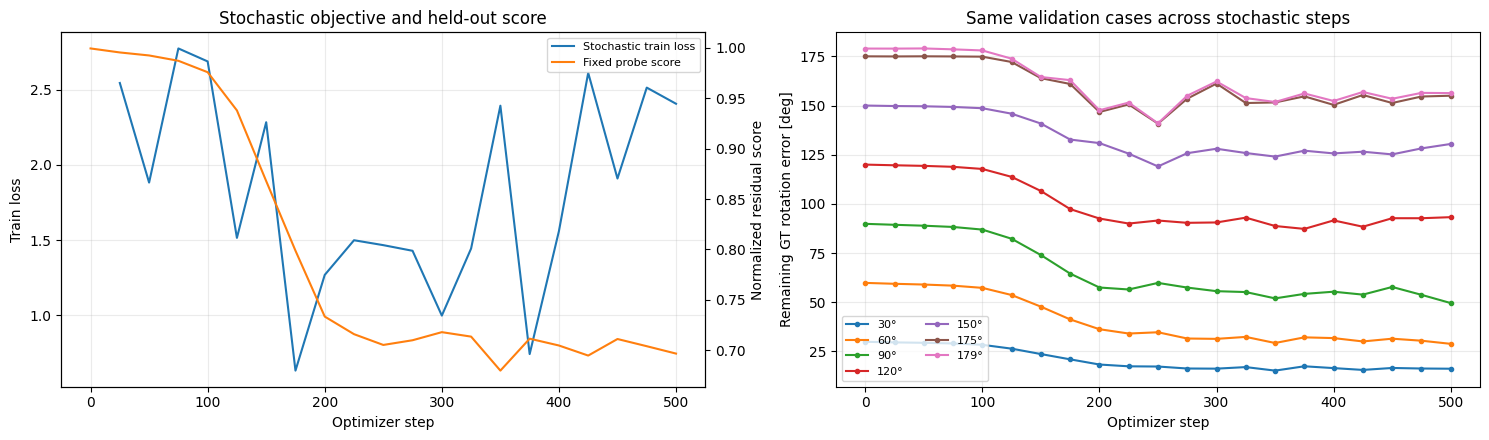

In [13]:
if stochastic_history:
    pd.DataFrame(stochastic_history).to_csv(RUN_DIR / 'stochastic_fm6d_history.csv', index=False)
    pd.DataFrame(stochastic_probe_rows).to_csv(RUN_DIR / 'stochastic_fm6d_angle_cases.csv', index=False)
    trace = pd.DataFrame(stochastic_history)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    axes[0].plot(trace.step, trace.train_loss, label='Stochastic train loss')
    ax0 = axes[0].twinx()
    ax0.plot(trace.step, trace.probe_score, color='C1', label='Fixed probe score')
    axes[0].set(xlabel='Optimizer step', ylabel='Train loss', title='Stochastic objective and held-out score')
    ax0.set_ylabel('Normalized residual score')
    h1,l1=axes[0].get_legend_handles_labels();h2,l2=ax0.get_legend_handles_labels();axes[0].legend(h1+h2,l1+l2,fontsize=8)
    for a in PROBE_ANGLES_DEG:
        if a == 0:
            continue
        axes[1].plot(trace.step, trace[f'angle_{int(a)}_deg'], marker='.', label=f'{int(a)}°')
    axes[1].set(xlabel='Optimizer step', ylabel='Remaining GT rotation error [deg]', title='Same validation cases across stochastic steps')
    axes[1].legend(ncol=2,fontsize=8)
    for ax in axes:ax.grid(alpha=.25)
    fig.tight_layout();fig.savefig(RUN_DIR / 'stochastic_fm6d_learning.png', dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)


### Stochastic endpoint behavior versus the trained 6D regression baseline

The best stochastic checkpoint can be step 0 if the combined score worsens. The final-step checkpoint is also saved to inspect the coarse/fine tradeoff, as learned from Notebook 58.


In [14]:
# Compare source 6D regression and the new FM (best or final stochastic) on identical faults.
source_probe_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(INIT_6D_CHECKPOINT, model=source_probe_model, map_location=DEVICE, restore_rng_state=False)
source_probe_df = evaluate_probe(source_probe_model, full_probe_batches)
source_probe_summary = print_probe_summary(source_probe_df, label='Original trained 6D regression')
del source_probe_model
for name, checkpoint_path in (('FM stochastic best', STOCHASTIC_CANDIDATE_PATH), ('FM stochastic last', STOCHASTIC_LAST_PATH)):
    if not checkpoint_path.is_file():
        print(name, 'not available')
        continue
    candidate_model = PooledCalibrationFlow6DModel(model_config, integration_steps=FM_INTEGRATION_STEPS, integration_method=FM_INTEGRATION_METHOD).to(device=DEVICE, dtype=DTYPE)
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    candidate_model.load_state_dict(checkpoint['model_state_dict'], strict=True)
    summary = print_probe_summary(evaluate_probe(candidate_model, full_probe_batches), label=f'{name}, step {checkpoint["step"]}')
    compared = source_probe_summary[['angle_deg', 'final_deg']].merge(summary[['angle_deg', 'final_deg']], on='angle_deg', suffixes=('_baseline', '_fm'))
    compared['improvement_deg'] = compared.final_deg_baseline - compared.final_deg_fm
    display(compared.round(3))
    del candidate_model


Original trained 6D regression | normalized residual score: 0.5774 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.245,-1.245,NaN,0.000,1.245,1.194,0.001
1,30.0,64,30.0,10.319,19.681,0.344,0.969,27.542,0.400,0.023
2,60.0,64,60.0,18.540,41.460,0.309,0.984,55.123,0.318,0.070
3,90.0,64,90.0,37.903,52.097,0.421,0.953,72.424,0.310,0.136
4,120.0,64,120.0,84.353,35.647,0.703,0.734,91.974,0.284,0.292
5,150.0,64,150.0,118.357,31.643,0.789,0.641,104.696,0.337,0.368
6,175.0,64,175.0,144.476,30.524,0.826,0.891,109.378,0.343,0.417
7,179.0,64,179.0,146.737,32.263,0.820,0.984,109.854,0.339,0.423


FM stochastic best, step 350 | normalized residual score: 0.6579 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.331,-1.331,NaN,0.000,1.331,1.979,0.001
1,30.0,64,30.0,13.962,16.038,0.465,1.000,23.142,0.387,0.040
2,60.0,64,60.0,28.510,31.490,0.475,0.984,50.843,0.314,0.098
3,90.0,64,90.0,50.565,39.435,0.562,0.953,74.128,0.306,0.181
4,120.0,64,120.0,85.062,34.938,0.709,0.766,90.788,0.299,0.306
5,150.0,64,150.0,118.801,31.199,0.792,0.703,98.466,0.579,0.413
6,175.0,64,175.0,149.399,25.601,0.854,0.781,104.249,0.455,0.489
7,179.0,64,179.0,152.543,26.457,0.852,0.922,105.136,0.435,0.496


,angle_deg,final_deg_baseline,final_deg_fm,improvement_deg
0,0.0,1.245,1.331,-0.086
1,30.0,10.319,13.962,-3.643
2,60.0,18.540,28.510,-9.970
3,90.0,37.903,50.565,-12.662
4,120.0,84.353,85.062,-0.709
5,150.0,118.357,118.801,-0.444
6,175.0,144.476,149.399,-4.923
7,179.0,146.737,152.543,-5.806


FM stochastic last, step 500 | normalized residual score: 0.6499 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.217,-1.217,NaN,0.000,1.217,0.877,0.001
1,30.0,64,30.0,14.377,15.623,0.479,0.984,21.928,0.476,0.035
2,60.0,64,60.0,26.378,33.622,0.440,0.984,46.486,0.425,0.088
3,90.0,64,90.0,48.712,41.288,0.541,0.938,65.093,0.443,0.163
4,120.0,64,120.0,84.982,35.018,0.708,0.766,80.418,0.411,0.300
5,150.0,64,150.0,119.738,30.262,0.798,0.688,89.907,0.408,0.399
6,175.0,64,175.0,149.286,25.714,0.853,0.844,98.217,0.424,0.465
7,179.0,64,179.0,151.070,27.930,0.844,0.984,99.416,0.432,0.472


,angle_deg,final_deg_baseline,final_deg_fm,improvement_deg
0,0.0,1.245,1.217,0.028
1,30.0,10.319,14.377,-4.058
2,60.0,18.540,26.378,-7.837
3,90.0,37.903,48.712,-10.809
4,120.0,84.353,84.982,-0.629
5,150.0,118.357,119.738,-1.382
6,175.0,144.476,149.286,-4.810
7,179.0,146.737,151.070,-4.333


## 10. Full FM training and checkpoint setup


In [15]:
def run_fm6d_epoch(loader, *, training, generator, max_batches=None):
    model.train(training)
    sums, counts = defaultdict(float), defaultdict(float)
    n_samples, optimizer_updates = 0, 0
    pending_samples, pending_microbatches = 0, 0
    started = time.perf_counter()
    if training:
        optimizer.zero_grad(set_to_none=True)

    def optimizer_flush():
        nonlocal pending_samples, pending_microbatches, optimizer_updates
        if pending_samples == 0:
            return
        for p in model.parameters():
            if p.grad is not None:
                p.grad.div_(pending_samples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        optimizer_updates += 1
        pending_samples, pending_microbatches = 0, 0

    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_id, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_id >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            augmented = make_training_window(base, generator=generator)
            loss, metrics = compute_fm_objective(augmented, generator=generator)
            n = len(next(iter(augmented.current_calibration.values())).transform)
            if training:
                (loss * n).backward()
                pending_samples += n
                pending_microbatches += 1
                if pending_microbatches >= GRADIENT_ACCUMULATION_STEPS:
                    optimizer_flush()
            for key, value in metrics.items():
                if key == 'active_rotation_count':
                    continue
                sums[key] += float(value) * n
                counts[key] += n
            n_samples += n
            del base, augmented, loss
        if training:
            optimizer_flush()
    if not n_samples:
        raise RuntimeError('Epoch used no samples')
    result = metric_average(sums, counts)
    result.update(n_samples=n_samples, optimizer_updates=optimizer_updates, elapsed_s=time.perf_counter()-started)
    
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result


BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'
HISTORY_PATH = RUN_DIR / 'training_fm6d_history.csv'
checkpoint_config = dict(run_name=RUN_NAME, architecture='PooledCalibrationFlow6DModel', calibration_keys=CALIBRATION_KEYS, source_checkpoint=str(INIT_6D_CHECKPOINT), head_mlp_lr=HEAD_MLP_LR, transformer_lr=TRANSFORMER_LR, batch_size=BATCH_SIZE, gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS, loss_weights=asdict(FLOW_LOSS_WEIGHTS), flow_mode=FLOW_MODE, flow_max_time=FLOW_MAX_TIME, flow_off_path=FLOW_OFF_PATH_PROBABILITY, flow_identity=FLOW_IDENTITY_PROBABILITY, train_integration=(TRAIN_INTEGRATION_STEPS, TRAIN_INTEGRATION_METHOD), inference_integration=(FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD), active_weight=ACTIVE_ROTATION_SUPERVISION_WEIGHT, fine_max_deg=FINE_ROTATION_MAX_DEG, coarse_range_deg=(COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), coarse_probability=COARSE_PRIOR_PROBABILITY, translation_prior_m=PRIOR_TRANSLATION_MAX_M, tau_reference_s=REFINED_TAU_BY_SENSOR_S, train_names=tuple(TRAIN_NAMES), val_names=tuple(VAL_NAMES), probe_angles=PROBE_ANGLES_DEG, probe_windows=PROBE_WINDOWS, probe_score_angles=PROBE_SCORE_ANGLES_DEG, coarse_probe_score_weight=PROBE_COARSE_SCORE_WEIGHT, zero_drift_weight=ZERO_DRIFT_WEIGHT)
train_generator = augmentation_generator(TRAIN_AUG_SEED)
start_epoch, global_step, best_score, best_epoch = 0, 0, float('inf'), 0
history=[]
if RESUME_FULL_TRAINING:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    metadata = torch.load(LAST_CHECKPOINT_PATH, map_location='cpu', weights_only=False)
    extra = metadata.get('extra_state') or {}
    if extra.get('config_fm6d') != checkpoint_config:
        raise RuntimeError('6D resume configuration differs; use a new RUN_NAME rather than resuming')
    loaded = load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator}, map_location=DEVICE, restore_rng_state=True)
    start_epoch, global_step = int(loaded.get('epoch', 0)), int(loaded.get('global_step', 0))
    best_score, best_epoch = float(extra['best_probe_score']), int(extra.get('best_epoch',0))
    if HISTORY_PATH.is_file():
        history=pd.read_csv(HISTORY_PATH).to_dict('records')
    print('Resumed exact 6D run at epoch', start_epoch)
else:
    if RUN_FULL_TRAINING and any(p.exists() for p in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH)):
        raise FileExistsError('Run files already exist; choose a new RUN_NAME or RESUME_FULL_TRAINING=True')
    if LOAD_STOCHASTIC_CANDIDATE_FOR_FULL:
        if not STOCHASTIC_CANDIDATE_PATH.is_file():
            raise FileNotFoundError(STOCHASTIC_CANDIDATE_PATH)
        candidate = torch.load(STOCHASTIC_CANDIDATE_PATH, map_location='cpu', weights_only=True)
        model.load_state_dict(candidate['model_state_dict'], strict=True)
        print('Explicitly initialized from stochastic candidate step', candidate['step'])
    else:
        print('Initialized full run from pretrained features + new FM head (preflight restored).')


def save_fm6d_checkpoint(path, epoch, metrics):
    save_training_checkpoint(path, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=metrics, generators={'train_shuffle':train_shuffle_generator, 'train_aug':train_generator}, extra_state={'config_fm6d': checkpoint_config, 'best_probe_score':best_score, 'best_epoch':best_epoch})


Initialized full run from pretrained features + new FM head (preflight restored).


## 11. Optional full training, with angular validation every epoch


In [16]:

if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [17]:
if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, NUM_EPOCHS):
        train_shuffle_generator.manual_seed(RANDOM_SEED + 12001 + epoch)
        train = run_fm6d_epoch(train_loader, training=True, generator=train_generator, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val = run_fm6d_epoch(val_loader, training=False, generator=augmentation_generator(VAL_AUG_SEED), max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        scheduler.step(val['loss_total'])
        global_step += train['optimizer_updates']
        improved = False
        row = dict(epoch=epoch+1, global_step=global_step, train_loss=train['loss_total'], val_loss=val['loss_total'], train_velocity=train['loss_velocity'], val_velocity=val['loss_velocity'], train_endpoint=train['loss_endpoint'], val_endpoint=val['loss_endpoint'], train_rotation_6d=train['loss_rotation_6d'], val_rotation_6d=val['loss_rotation_6d'], train_translation=train['loss_translation'], val_translation=val['loss_translation'], train_tau=train['loss_tau'], val_tau=val['loss_tau'], train_active_deg=train['active_rotation_error_deg'], val_active_deg=val['active_rotation_error_deg'], head_mlp_lr=optimizer.param_groups[1]['lr'], transformer_lr=optimizer.param_groups[0]['lr'])
        if (epoch+1) % PROBE_EVERY_EPOCHS == 0:
            probe = evaluate_probe(model, full_probe_batches)
            summary = summarize_probe(probe)
            score = probe_score(summary)
            row['probe_score'] = score
            for angle in PROBE_ANGLES_DEG:
                sub=summary.loc[summary.angle_deg==angle].iloc[0]
                row[f'probe_{int(angle)}_final_deg'] = float(sub.final_deg)
                row[f'probe_{int(angle)}_improves'] = float(sub.fraction_improving)
            if score < best_score:
                improved = True
                best_score, best_epoch = score, epoch+1
                save_fm6d_checkpoint(BEST_CHECKPOINT_PATH, epoch+1, row)
                # print('New best angular probe checkpoint at epoch', best_epoch, '| score',round(score,4))
        history.append(row)
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        save_fm6d_checkpoint(LAST_CHECKPOINT_PATH, epoch+1, row)
        angles_report=', '.join(f'{int(a)}°={row[f"probe_{int(a)}_final_deg"]:.1f}°' for a in (0.0,30.0,90.0,120.0,150.0,175.0,179.0)) if 'probe_score' in row else 'not evaluated'
        print(f'Epoch {epoch+1:3d}/{NUM_EPOCHS} train={train["loss_total"]:.4f} val={val["loss_total"]:.4f} | fixed probe: {angles_report} | LR={row["head_mlp_lr"]:.1e}/{row["transformer_lr"]:.1e}'+ (" BEST" if improved else ""), flush=True)
else:
    print('Full training disabled.')


Epoch   1/100 train=3.1338 val=1.9678 | fixed probe: 0°=1.1°, 30°=22.7°, 90°=71.5°, 120°=101.8°, 150°=131.8°, 175°=159.4°, 179°=162.1° | LR=3.0e-04/3.0e-05 BEST
Epoch   2/100 train=1.6204 val=1.5030 | fixed probe: 0°=0.8°, 30°=15.8°, 90°=50.0°, 120°=85.6°, 150°=124.1°, 175°=152.1°, 179°=154.3° | LR=3.0e-04/3.0e-05 BEST
Epoch   3/100 train=1.5341 val=1.4583 | fixed probe: 0°=2.0°, 30°=14.3°, 90°=48.3°, 120°=84.1°, 150°=117.4°, 175°=144.3°, 179°=146.0° | LR=3.0e-04/3.0e-05 BEST
Epoch   4/100 train=1.4164 val=1.4498 | fixed probe: 0°=1.3°, 30°=11.2°, 90°=45.1°, 120°=86.1°, 150°=119.9°, 175°=146.1°, 179°=148.2° | LR=3.0e-04/3.0e-05 BEST
Epoch   5/100 train=1.4277 val=1.4095 | fixed probe: 0°=1.5°, 30°=12.1°, 90°=49.3°, 120°=89.7°, 150°=122.6°, 175°=150.6°, 179°=152.4° | LR=3.0e-04/3.0e-05
Epoch   6/100 train=1.3697 val=1.4180 | fixed probe: 0°=1.4°, 30°=10.8°, 90°=48.1°, 120°=91.4°, 150°=122.8°, 175°=145.8°, 179°=148.3° | LR=3.0e-04/3.0e-05
Epoch   7/100 train=1.4410 val=1.4141 | fixed pro

## 12. Training curves, velocity/endpoint components and per-angle validation


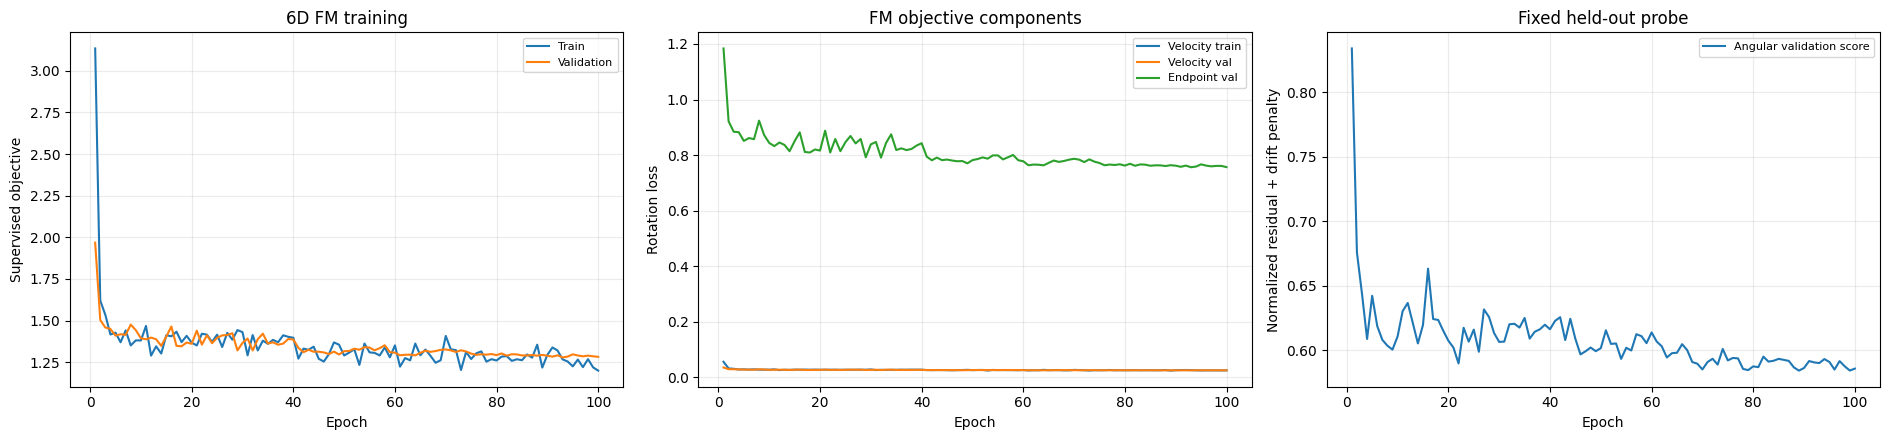

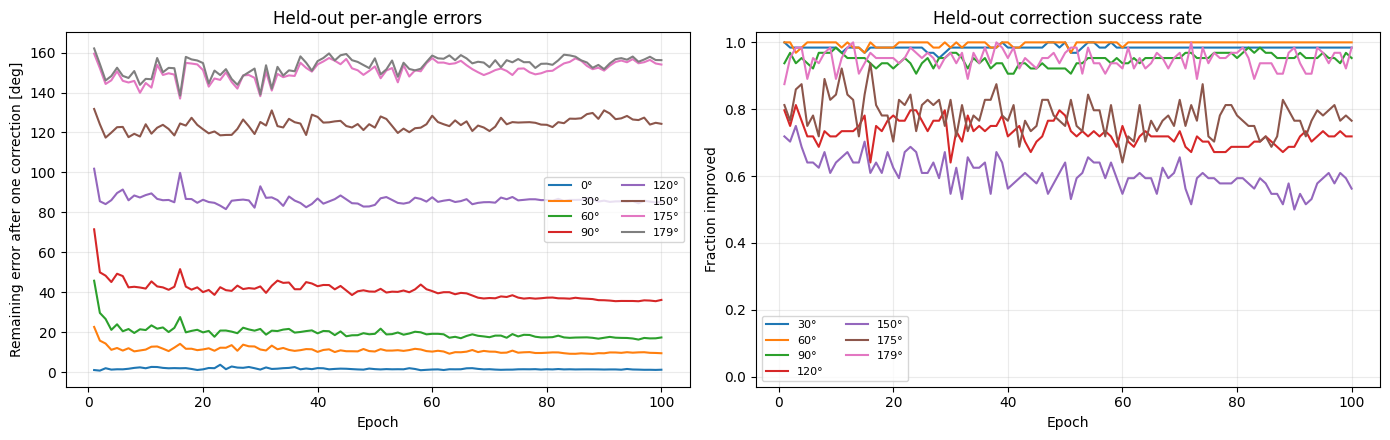

In [18]:
if HISTORY_PATH.is_file():
    train_history = pd.read_csv(HISTORY_PATH)
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
    axes[0].plot(train_history.epoch, train_history.train_loss, label='Train')
    axes[0].plot(train_history.epoch, train_history.val_loss, label='Validation')
    axes[0].set(xlabel='Epoch',ylabel='Supervised objective',title='6D FM training')
    axes[1].plot(train_history.epoch, train_history.train_velocity, label='Velocity train')
    axes[1].plot(train_history.epoch, train_history.val_velocity, label='Velocity val')
    axes[1].plot(train_history.epoch, train_history.val_endpoint, label='Endpoint val')
    axes[1].set(xlabel='Epoch',ylabel='Rotation loss',title='FM objective components')
    axes[2].plot(train_history.epoch, train_history.probe_score, label='Angular validation score')
    axes[2].set(xlabel='Epoch',ylabel='Normalized residual + drift penalty',title='Fixed held-out probe')
    for ax in axes:ax.grid(alpha=.25);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(RUN_DIR / 'fm6d_training_objectives.png',dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)

    fig, axes=plt.subplots(1, 2, figsize=(14, 4.5))
    for a in PROBE_ANGLES_DEG:
        axes[0].plot(train_history.epoch, train_history[f'probe_{int(a)}_final_deg'],label=f'{int(a)}°')
    axes[0].set(xlabel='Epoch',ylabel='Remaining error after one correction [deg]',title='Held-out per-angle errors')
    for a in PROBE_ANGLES_DEG:
        if a == 0:continue
        axes[1].plot(train_history.epoch, train_history[f'probe_{int(a)}_improves'],label=f'{int(a)}°')
    axes[1].set(xlabel='Epoch',ylabel='Fraction improved',ylim=(-0.03,1.03),title='Held-out correction success rate')
    for ax in axes:ax.grid(alpha=.25);ax.legend(ncol=2,fontsize=8)
    fig.tight_layout();fig.savefig(RUN_DIR / 'fm6d_training_angles.png',dpi=170)
    if SHOW_PLOTS:plt.show()
    else:plt.close(fig)
else:
    print('No full training history yet.')


## 13. Paired one-step comparison: original 6D regression versus trained 6D FM


Best 6D checkpoint | normalized residual score: 0.5842 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.395,-1.395,NaN,0.000,1.395,1.271,0.001
1,30.0,64,30.0,9.527,20.473,0.318,0.984,28.296,0.280,0.015
2,60.0,64,60.0,16.778,43.222,0.280,1.000,56.936,0.164,0.064
3,90.0,64,90.0,36.073,53.927,0.401,0.953,74.558,0.147,0.133
4,120.0,64,120.0,85.400,34.600,0.712,0.688,92.870,0.110,0.295
5,150.0,64,150.0,126.804,23.196,0.845,0.578,106.144,0.178,0.379
6,175.0,64,175.0,152.415,22.585,0.871,0.797,111.888,0.188,0.406
7,179.0,64,179.0,153.810,25.190,0.859,0.969,111.890,0.179,0.409


Paired residual reduction (positive is better):


,mean,median,std,count
angle_deg,,,,
0.0,-0.150,-0.135,0.859,64
30.0,0.792,1.073,3.021,64
60.0,1.762,0.708,9.232,64
90.0,1.830,4.451,11.155,64
120.0,-1.047,0.262,18.990,64
150.0,-8.447,-4.803,33.211,64
175.0,-7.939,-3.023,47.926,64
179.0,-7.072,-3.113,42.116,64


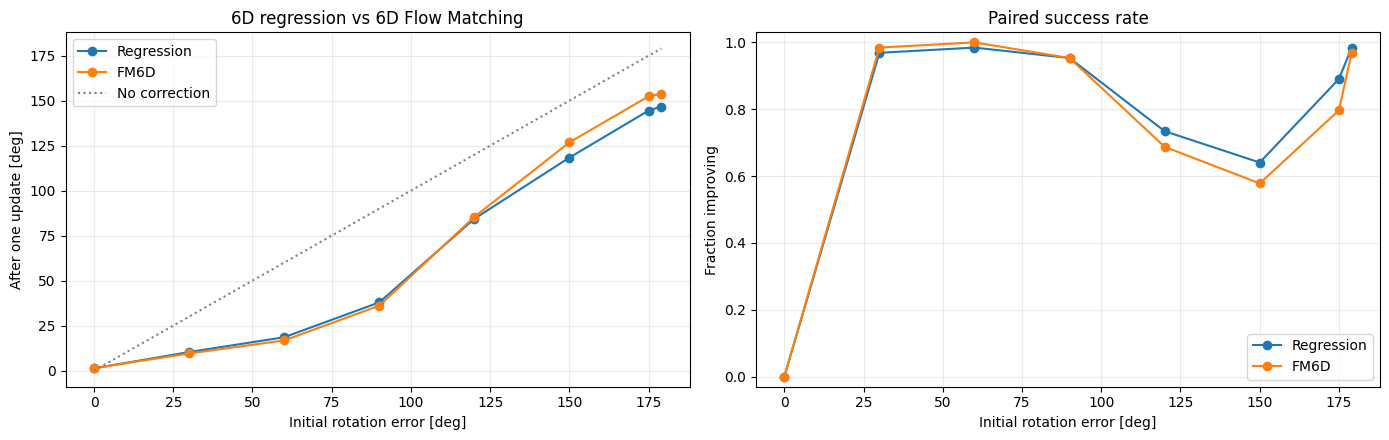

In [19]:
if BEST_CHECKPOINT_PATH.is_file():
    model.eval()
    previous = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
    try:
        load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
        best_probe_df = evaluate_probe(model, full_probe_batches)
        best_probe_summary = print_probe_summary(best_probe_df, label='Best 6D checkpoint')
        paired = source_probe_df.merge(best_probe_df, on=['angle_deg','physical_index','axis_seed','fault_key'], suffixes=('_initial','_trained'),validate='one_to_one')
        paired['error_gain_deg'] = paired.after_deg_initial - paired.after_deg_trained
        print('Paired residual reduction (positive is better):')
        display(paired.groupby('angle_deg').error_gain_deg.agg(['mean','median','std','count']).round(3))
        best_probe_df.to_csv(RUN_DIR/'best_fm6d_angle_cases.csv',index=False)
        paired.to_csv(RUN_DIR/'paired_regression_vs_fm6d.csv',index=False)
        fig,axes=plt.subplots(1,2,figsize=(14,4.5))
        for label,sub in [('Regression',source_probe_summary),('FM6D',best_probe_summary)]:
            axes[0].plot(sub.angle_deg,sub.final_deg,marker='o',label=label)
            axes[1].plot(sub.angle_deg,sub.fraction_improving,marker='o',label=label)
        axes[0].plot(PROBE_ANGLES_DEG,PROBE_ANGLES_DEG,linestyle=':',color='gray',label='No correction')
        axes[0].set(xlabel='Initial rotation error [deg]',ylabel='After one update [deg]',title='6D regression vs 6D Flow Matching')
        axes[1].set(xlabel='Initial rotation error [deg]',ylabel='Fraction improving',ylim=(-0.03,1.03),title='Paired success rate')
        for ax in axes:ax.grid(alpha=.25);ax.legend()
        fig.tight_layout();fig.savefig(RUN_DIR/'best_fm6d_angle_comparison.png',dpi=170)
        if SHOW_PLOTS:plt.show()
        else:plt.close(fig)
    finally:
        model.load_state_dict(previous,strict=True)
        del previous
else:
    print('No best checkpoint available yet.')


## 14. Optional test-split evaluation (off by default)


In [20]:
if RUN_FINAL_TEST_EVALUATION:
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(BEST_CHECKPOINT_PATH)
    previous = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
    try:
        load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
        test_probe_batches = build_probe_batches(test_dataset, n_windows=PROBE_WINDOWS, batch_size=PROBE_BATCH_SIZE, seed=TEST_AUG_SEED + 100000, axis_seeds=PROBE_AXIS_SEEDS)
        test_probe_frame = evaluate_probe(model, test_probe_batches)
        print_probe_summary(test_probe_frame, label='FINAL TEST: 6D FM checkpoint')
        test_probe_frame.to_csv(RUN_DIR / 'final_test_fm6d_angle_cases.csv',index=False)
    finally:
        model.load_state_dict(previous,strict=True)
        del previous
else:
    print('Test split untouched. Set RUN_FINAL_TEST_EVALUATION=True only for the final comparison.')


FINAL TEST: 6D FM checkpoint | normalized residual score: 0.6229 | lower is better


,angle_deg,n,before_deg,final_deg,improvement_deg,relative_remaining,fraction_improving,predicted_step_deg,healthy_drift_deg,error_6d
0,0.0,64,0.0,1.546,-1.546,NaN,0.000,1.546,0.949,0.001
1,30.0,64,30.0,8.661,21.339,0.289,1.000,28.538,0.242,0.014
2,60.0,64,60.0,17.906,42.094,0.298,1.000,55.039,0.123,0.064
3,90.0,64,90.0,44.635,45.365,0.496,0.844,72.756,0.091,0.165
4,120.0,64,120.0,96.172,23.828,0.801,0.609,92.332,0.092,0.323
5,150.0,64,150.0,133.134,16.866,0.888,0.578,102.529,0.109,0.409
6,175.0,64,175.0,157.239,17.761,0.899,0.766,106.457,0.118,0.441
7,179.0,64,179.0,159.264,19.736,0.890,0.969,106.622,0.117,0.442


## 15. Interpretation

Success is **rollout stability and success below 10°/30°**, especially at 150–179°, not merely decreasing FM velocity loss. Both the source and new models use identical physical windows and prior perturbations.

A 6D Euclidean path is not a path on SO(3); intermediate 6D vectors may be degenerate for 180° rotations, although the final rotation is projected. This prototype deliberately tests that choice.

The new FM head is not pretrained. Its computational latency is substantially higher than direct 6D regression because midpoint integration evaluates the velocity field twice per step. Measure that tradeoff before deciding to adopt FM.


In [21]:
print('Run:', RUN_DIR)
print('Model:', type(model).__name__, '| Flow state / velocity = 6 rotation + 3 translation + 1 tau')
print('Backbone initialized from trained 6D regression:', INIT_6D_CHECKPOINT)
print('All trainable:', all(p.requires_grad for p in model.parameters()))
print('Optimizer LRs:', [(group['name'], group['lr']) for group in optimizer.param_groups])
print('Stochastic best/last:', STOCHASTIC_CANDIDATE_PATH, STOCHASTIC_LAST_PATH)
print('Full checkpoint:', BEST_CHECKPOINT_PATH, '| exists:', BEST_CHECKPOINT_PATH.is_file())


Run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_6d.1_full_range
Model: PooledCalibrationFlow6DModel | Flow state / velocity = 6 rotation + 3 translation + 1 tau
Backbone initialized from trained 6D regression: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
All trainable: True
Optimizer LRs: [('transformer', 3.7499999999999997e-06), ('pooler_mlp_fm_head', 3.75e-05)]
Stochastic best/last: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_6d.1_full_range/stochastic_best_fm6d_state.pt /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_6d.1_full_range/stochastic_last_fm6d_state.pt
Full checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_6d.1_full_range/best.pt | exists: True


## 16. Matched chronological rollouts: trained 6D regression vs 6D FM

Same two validation sequences, starting positions, calibration truths, fault axes, and five-second windows. The two models use the **same 6D updater**. Each subplot shows only two mean curves, with independent median/p90/success statistics in tables. Default is 64 cases per angle per model.


In [22]:

# Appendix A. Matched, batched rollouts: pretrained 6D regression vs trained 6D FM (stochastic best or full best).
# Use the same validation cases, sensor keys, rotation axes, static true calibration and chronological windows for both models.

# Rollout from the LAST stochastic candidate (default, full training off)
# or the best full-training checkpoint (when RUN_FULL_TRAINING=True).
ROLL59_BASELINE_CHECKPOINT = BASELINE_6D_CHECKPOINT
ROLL59_USE_FULL_BEST = RUN_FULL_TRAINING and BEST_CHECKPOINT_PATH.is_file()
ROLL59_FM_CHECKPOINT = BEST_CHECKPOINT_PATH if ROLL59_USE_FULL_BEST else STOCHASTIC_LAST_PATH
ROLL59_DATASET = val_dataset
ROLL59_SEQUENCES = tuple(VAL_NAMES)
ROLL59_NUM_WINDOWS = 12
ROLL59_STARTS_PER_SEQUENCE = 2
ROLL59_CALIBRATIONS_PER_START = 8
ROLL59_CALIBRATION_BATCH_SIZE = 4
ROLL59_FAULT_KEYS = ('lidar', 'lidar_right')
ROLL59_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
ROLL59_UPDATE_ALL_KEYS = True
ROLL59_SEED = VAL_AUG_SEED + 1_900_000
ROLL59_OUTPUT_DIR = RUN_DIR / 'plots' / ('rollout_full_fm_vs_regression' if ROLL59_USE_FULL_BEST else 'rollout_stochastic_fm_vs_regression')
ROLL59_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in (ROLL59_BASELINE_CHECKPOINT, ROLL59_FM_CHECKPOINT):
    if not path.is_file():
        raise FileNotFoundError(path)
if not set(ROLL59_FAULT_KEYS).issubset(CALIBRATION_KEYS):
    raise ValueError('Unknown rollout fault keys')

roll59_baseline_model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
roll59_tuned_model = PooledCalibrationFlow6DModel(model_config, integration_steps=FM_INTEGRATION_STEPS, integration_method=FM_INTEGRATION_METHOD).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(ROLL59_BASELINE_CHECKPOINT, model=roll59_baseline_model, map_location=DEVICE, restore_rng_state=False)
if ROLL59_USE_FULL_BEST:
    load_training_checkpoint(ROLL59_FM_CHECKPOINT, model=roll59_tuned_model, map_location=DEVICE, restore_rng_state=False)
else:
    roll59_snapshot = torch.load(ROLL59_FM_CHECKPOINT, map_location='cpu', weights_only=True)
    roll59_tuned_model.load_state_dict(roll59_snapshot['model_state_dict'], strict=True)
    print('Stochastic checkpoint step:', roll59_snapshot['step'], '| probe score:', roll59_snapshot['score'])
    del roll59_snapshot

roll59_models = {
    'Trained 6D regression': roll59_baseline_model.eval().requires_grad_(False),
    '6D Flow Matching': roll59_tuned_model.eval().requires_grad_(False),
}
print('Trained 6D regression:', ROLL59_BASELINE_CHECKPOINT)
print('New 6D FM:', ROLL59_FM_CHECKPOINT)
print('Matched rollout cases per angle per model:', len(ROLL59_SEQUENCES) * ROLL59_STARTS_PER_SEQUENCE * ROLL59_CALIBRATIONS_PER_START * len(ROLL59_FAULT_KEYS))


def roll59_copy_states(states):
    """Clone calibration tensors so different model rollouts cannot contaminate one another."""
    return {
        key: replace(state, transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone())
        for key, state in states.items()
    }


def roll59_repeat_tensor(value, copies):
    """Repeat the batch dimension of a single-window tensor, preserving dtype and device."""
    if value is None or not torch.is_tensor(value) or value.ndim == 0:
        return value
    if value.shape[0] != 1:
        raise ValueError(f'Expected a single-item source batch, got shape {tuple(value.shape)}')
    return value.expand(copies, *value.shape[1:]).clone()


def roll59_repeat_window(window, copies):
    """Make an independent batched copy of one raw physical window before truth augmentation."""
    streams = {
        key: replace(
            stream,
            values=roll59_repeat_tensor(stream.values, copies),
            timestamps=roll59_repeat_tensor(stream.timestamps, copies),
            sample_mask=roll59_repeat_tensor(stream.sample_mask, copies),
            interval_start_timestamps=roll59_repeat_tensor(stream.interval_start_timestamps, copies),
        )
        for key, stream in window.streams.items()
    }

    states = {
        key: replace(
            state,
            transform=roll59_repeat_tensor(state.transform, copies),
            time_offset=roll59_repeat_tensor(state.time_offset, copies),
        )
        for key, state in window.current_calibration.items()
    }

    targets = None if window.targets is None else {
        key: replace(
            target,
            next_transform=roll59_repeat_tensor(target.next_transform, copies),
            next_time_offset=roll59_repeat_tensor(target.next_time_offset, copies),
            change_label=roll59_repeat_tensor(target.change_label, copies),
            change_time=roll59_repeat_tensor(target.change_time, copies),
        )
        for key, target in window.targets.items()
    }

    indices = window.dataset_indices
    if torch.is_tensor(indices) and indices.ndim > 0:
        indices = roll59_repeat_tensor(indices, copies)
    elif isinstance(indices, (tuple, list)) and len(indices) == 1:
        indices = type(indices)(list(indices) * copies)

    return WindowBatch(
        streams=streams,
        current_calibration=states,
        metadata=dict(window.metadata),
        targets=targets,
        dataset_indices=indices,
    )


def roll59_sequence_indices(dataset, sequence, num_windows, num_starts):
    """Return equally spaced chronological blocks from a specific sequence."""
    indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=np.int64)
    max_start = len(indices) - num_windows

    if max_start < 0:
        raise ValueError(f'{sequence}: {len(indices)} windows available but {num_windows} requested')

    starts = np.unique(np.linspace(0, max_start, min(num_starts, max_start + 1)).round().astype(int))
    return [indices[start:start + num_windows] for start in starts]


@torch.inference_mode()
def roll59_physical_sequence(indices, physical_seed, batch_size):
    """Generate distinct true calibrations per batch item, constant through all chronological windows.

    Each chronological raw window is repeated before augmentation. Reinitializing the truth
    generator with the same seed for each window guarantees that case j has the same physically
    consistent true calibration at every time, while different cases j have different truths.
    """
    physical_windows = []
    truth = None

    for index in indices:
        base = window_batch_to(collate_windows([ROLL59_DATASET[int(index)]]), DEVICE, dtype=DTYPE)
        batched = roll59_repeat_window(base, batch_size)
        physical = physical_augmenter(batched, generator=augmentation_generator(physical_seed)).augmented_window

        if truth is None:
            truth = roll59_copy_states(physical.current_calibration)
        else:
            for key in CALIBRATION_KEYS:
                torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

        physical_windows.append(physical)

    return physical_windows, truth


@torch.inference_mode()
def roll59_run_comparison():
    """Compare old and fine-tuned 6D predictors across identical complete feedback trajectories."""
    records = []

    for sequence_id, sequence in enumerate(ROLL59_SEQUENCES):
        blocks = roll59_sequence_indices(ROLL59_DATASET, sequence, ROLL59_NUM_WINDOWS, ROLL59_STARTS_PER_SEQUENCE)

        for start_id, indices in enumerate(blocks):
            for batch_start in range(0, ROLL59_CALIBRATIONS_PER_START, ROLL59_CALIBRATION_BATCH_SIZE):
                batch_size = min(ROLL59_CALIBRATION_BATCH_SIZE, ROLL59_CALIBRATIONS_PER_START - batch_start)
                physical_seed = ROLL59_SEED + 1_000_003 * sequence_id + 100_003 * start_id + 1_009 * batch_start

                physical_windows, truth = roll59_physical_sequence(indices, physical_seed, batch_size)

                axis_gen = augmentation_generator(physical_seed + 35_011)
                axes = torch.randn(batch_size, 3, generator=axis_gen, device=DEVICE, dtype=DTYPE)
                axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-9)

                for fault_key in ROLL59_FAULT_KEYS:
                    for angle in ROLL59_ANGLES_DEG:
                        xi = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                        tau = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}

                        xi[fault_key][:, :3] = axes * np.deg2rad(float(angle))
                        initial = apply_independent_prior_faults(truth, xi, tau)
                        keys_to_update = CALIBRATION_KEYS if ROLL59_UPDATE_ALL_KEYS else (fault_key,)

                        for model_name, evaluation_model in roll59_models.items():
                            states = roll59_copy_states(initial)

                            for step in range(ROLL59_NUM_WINDOWS + 1):
                                active_error = rotation_geodesic_deg(
                                    states[fault_key].transform[:, :3, :3],
                                    truth[fault_key].transform[:, :3, :3],
                                ).detach().cpu().numpy()

                                healthy_errors = torch.stack([
                                    rotation_geodesic_deg(
                                        states[key].transform[:, :3, :3],
                                        truth[key].transform[:, :3, :3],
                                    )
                                    for key in CALIBRATION_KEYS if key != fault_key
                                ], dim=0).mean(dim=0).detach().cpu().numpy()

                                for j in range(batch_size):
                                    records.append(dict(
                                        sequence=sequence,
                                        start_index=int(indices[0]),
                                        calibration_id=int(batch_start + j),
                                        physical_seed=int(physical_seed),
                                        fault_key=fault_key,
                                        angle_deg=float(angle),
                                        model=model_name,
                                        step=step,
                                        elapsed_s=step * WINDOW_STRIDE_S,
                                        axis_x=float(axes[j, 0]),
                                        axis_y=float(axes[j, 1]),
                                        axis_z=float(axes[j, 2]),
                                        active_error_deg=float(active_error[j]),
                                        healthy_error_deg=float(healthy_errors[j]),
                                    ))

                                if step == ROLL59_NUM_WINDOWS:
                                    break

                                input_window = clone_with_current_calibration(physical_windows[step], states)
                                prediction = model_predictions(input_window, model_override=evaluation_model).predictions

                                states = apply_calibration_6d_update(states, prediction, keys_to_update=keys_to_update)

            print(
                f'Completed {sequence} start {start_id + 1}/{len(blocks)} '
                f'({ROLL59_CALIBRATIONS_PER_START} calibrations, {len(ROLL59_FAULT_KEYS)} fault keys)',
                flush=True,
            )

    return pd.DataFrame.from_records(records)


roll59_df = roll59_run_comparison()

roll59_df['improving'] = np.where(
    roll59_df.angle_deg > 0.0,
    (roll59_df.active_error_deg < roll59_df.angle_deg - 1e-3).astype(float),
    np.nan,
)

roll59_summary = roll59_df.groupby(['angle_deg', 'model', 'step'], as_index=False).agg(
    mean_error_deg=('active_error_deg', 'mean'),
    median_error_deg=('active_error_deg', 'median'),
    p25_error_deg=('active_error_deg', lambda x: x.quantile(0.25)),
    p75_error_deg=('active_error_deg', lambda x: x.quantile(0.75)),
    p90_error_deg=('active_error_deg', lambda x: x.quantile(0.90)),
    mean_healthy_drift_deg=('healthy_error_deg', 'mean'),
    fraction_improving=('improving', 'mean'),
    fraction_below_10deg=('active_error_deg', lambda x: (x < 10.0).mean()),
    fraction_below_30deg=('active_error_deg', lambda x: (x < 30.0).mean()),
    n_cases=('active_error_deg', 'size'),
)

roll59_df.to_csv(ROLL59_OUTPUT_DIR / 'matched_rollout_individual_trajectories.csv', index=False)
roll59_summary.to_csv(ROLL59_OUTPUT_DIR / 'matched_rollout_mean_quantiles.csv', index=False)

expected = len(ROLL59_SEQUENCES) * ROLL59_STARTS_PER_SEQUENCE * ROLL59_CALIBRATIONS_PER_START * len(ROLL59_FAULT_KEYS)
counts = roll59_summary.n_cases.unique()

if len(counts) != 1 or counts[0] != expected:
    raise AssertionError(f'Unexpected case counts: observed {counts}, expected {expected}. Check sequence start uniqueness.')

print(f'Validated {expected} matched rollout cases per angle and model, each lasting {ROLL59_NUM_WINDOWS} windows.')

selected_steps = sorted(set((0, 1, 3, 6, ROLL59_NUM_WINDOWS)) & set(roll59_summary.step.unique()))

display(
    roll59_summary[roll59_summary.step.isin(selected_steps)]
    .pivot_table(index=['angle_deg', 'model'], columns='step', values='mean_error_deg')
    .round(2)
)

print('Final rollout statistics (mean, median, 90th percentile, improvement probability, success below 10°):')

display(
    roll59_summary[roll59_summary.step == ROLL59_NUM_WINDOWS][[
        'angle_deg', 'model', 'n_cases', 'mean_error_deg', 'median_error_deg',
        'p90_error_deg', 'fraction_improving', 'fraction_below_10deg', 'fraction_below_30deg',
        'mean_healthy_drift_deg',
    ]].round(3)
)

print('Final errors by physical sequence and faulted sensor:')

roll59_by_sequence = (
    roll59_df[roll59_df.step == ROLL59_NUM_WINDOWS]
    .groupby(['sequence', 'fault_key', 'angle_deg', 'model'], as_index=False)
    .agg(
        mean_error_deg=('active_error_deg', 'mean'),
        fraction_improving=('improving', 'mean'),
        n_cases=('active_error_deg', 'size'),
    )
)

roll59_by_sequence.to_csv(ROLL59_OUTPUT_DIR / 'rollout_by_sequence_and_fault.csv', index=False)

display(
    roll59_by_sequence[
        roll59_by_sequence.angle_deg.isin((120.0, 150.0, 175.0, 179.0))
    ].round(3)
)


Trained 6D regression: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
New 6D FM: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_6d.1_full_range/best.pt
Matched rollout cases per angle per model: 64


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Completed Urban26 start 1/2 (8 calibrations, 2 fault keys)
Completed Urban26 start 2/2 (8 calibrations, 2 fault keys)
Completed Urban28 start 1/2 (8 calibrations, 2 fault keys)
Completed Urban28 start 2/2 (8 calibrations, 2 fault keys)
Validated 64 matched rollout cases per angle and model, each lasting 12 windows.


step                                0       1       3       6       12
angle_deg model                                                       
0.0       6D Flow Matching         0.0    1.32    1.77    2.87    5.13
          Trained 6D regression    0.0    1.06    1.09    1.60    2.87
30.0      6D Flow Matching        30.0    8.58    7.06    5.59    5.15
          Trained 6D regression   30.0    8.22    6.87    6.30    4.60
60.0      6D Flow Matching        60.0   14.79   11.81    9.56    6.29
          Trained 6D regression   60.0   15.63   12.64   10.72    5.83
90.0      6D Flow Matching        90.0   33.71   25.44   25.89   23.69
          Trained 6D regression   90.0   34.86   26.50   24.39   18.08
120.0     6D Flow Matching       120.0   85.73   81.16   80.85   81.93
          Trained 6D regression  120.0   88.39   84.43   85.49   90.09
150.0     6D Flow Matching       150.0  118.41  118.90  118.97  113.79
          Trained 6D regression  150.0  123.61  126.57  127.95  131.78
175.0     6D Flow Matching       175.0  150.94  157.90  158.91  164.67
          Trained 6D regression  175.0  146.76  148.54  149.48  152.02
179.0     6D Flow Matching       179.0  152.72  156.26  157.03  160.67
          Trained 6D regression  179.0  146.87  150.33  151.15  156.29

Final rollout statistics (mean, median, 90th percentile, improvement probability, success below 10°):


,angle_deg,model,n_cases,mean_error_deg,median_error_deg,p90_error_deg,fraction_improving,fraction_below_10deg,fraction_below_30deg,mean_healthy_drift_deg
12,0.0,6D Flow Matching,64,5.132,4.622,9.595,NaN,1.000,1.000,4.419
25,0.0,Trained 6D regression,64,2.868,2.622,6.710,NaN,1.000,1.000,2.715
38,30.0,6D Flow Matching,64,5.148,4.422,9.560,1.000,0.938,1.000,4.122
51,30.0,Trained 6D regression,64,4.597,3.254,7.230,1.000,0.953,1.000,2.741
64,60.0,6D Flow Matching,64,6.285,4.790,11.103,1.000,0.875,1.000,4.039
77,60.0,Trained 6D regression,64,5.826,3.493,14.052,1.000,0.844,1.000,2.696
90,90.0,6D Flow Matching,64,23.688,5.468,84.199,0.891,0.719,0.859,3.976
103,90.0,Trained 6D regression,64,18.081,5.802,36.587,0.938,0.688,0.875,2.821
116,120.0,6D Flow Matching,64,81.934,12.543,177.850,0.547,0.438,0.531,4.029
129,120.0,Trained 6D regression,64,90.095,122.409,178.003,0.500,0.453,0.484,2.873


Final errors by physical sequence and faulted sensor:


,sequence,fault_key,angle_deg,model,mean_error_deg,fraction_improving,n_cases
8,Urban26,lidar,120.0,6D Flow Matching,101.786,0.438,16
9,Urban26,lidar,120.0,Trained 6D regression,100.433,0.438,16
10,Urban26,lidar,150.0,6D Flow Matching,115.937,0.375,16
11,Urban26,lidar,150.0,Trained 6D regression,142.587,0.250,16
12,Urban26,lidar,175.0,6D Flow Matching,166.178,0.375,16
13,Urban26,lidar,175.0,Trained 6D regression,152.612,0.500,16
14,Urban26,lidar,179.0,6D Flow Matching,155.914,0.688,16
15,Urban26,lidar,179.0,Trained 6D regression,163.907,0.938,16
24,Urban26,lidar_right,120.0,6D Flow Matching,99.189,0.438,16
25,Urban26,lidar_right,120.0,Trained 6D regression,95.529,0.500,16


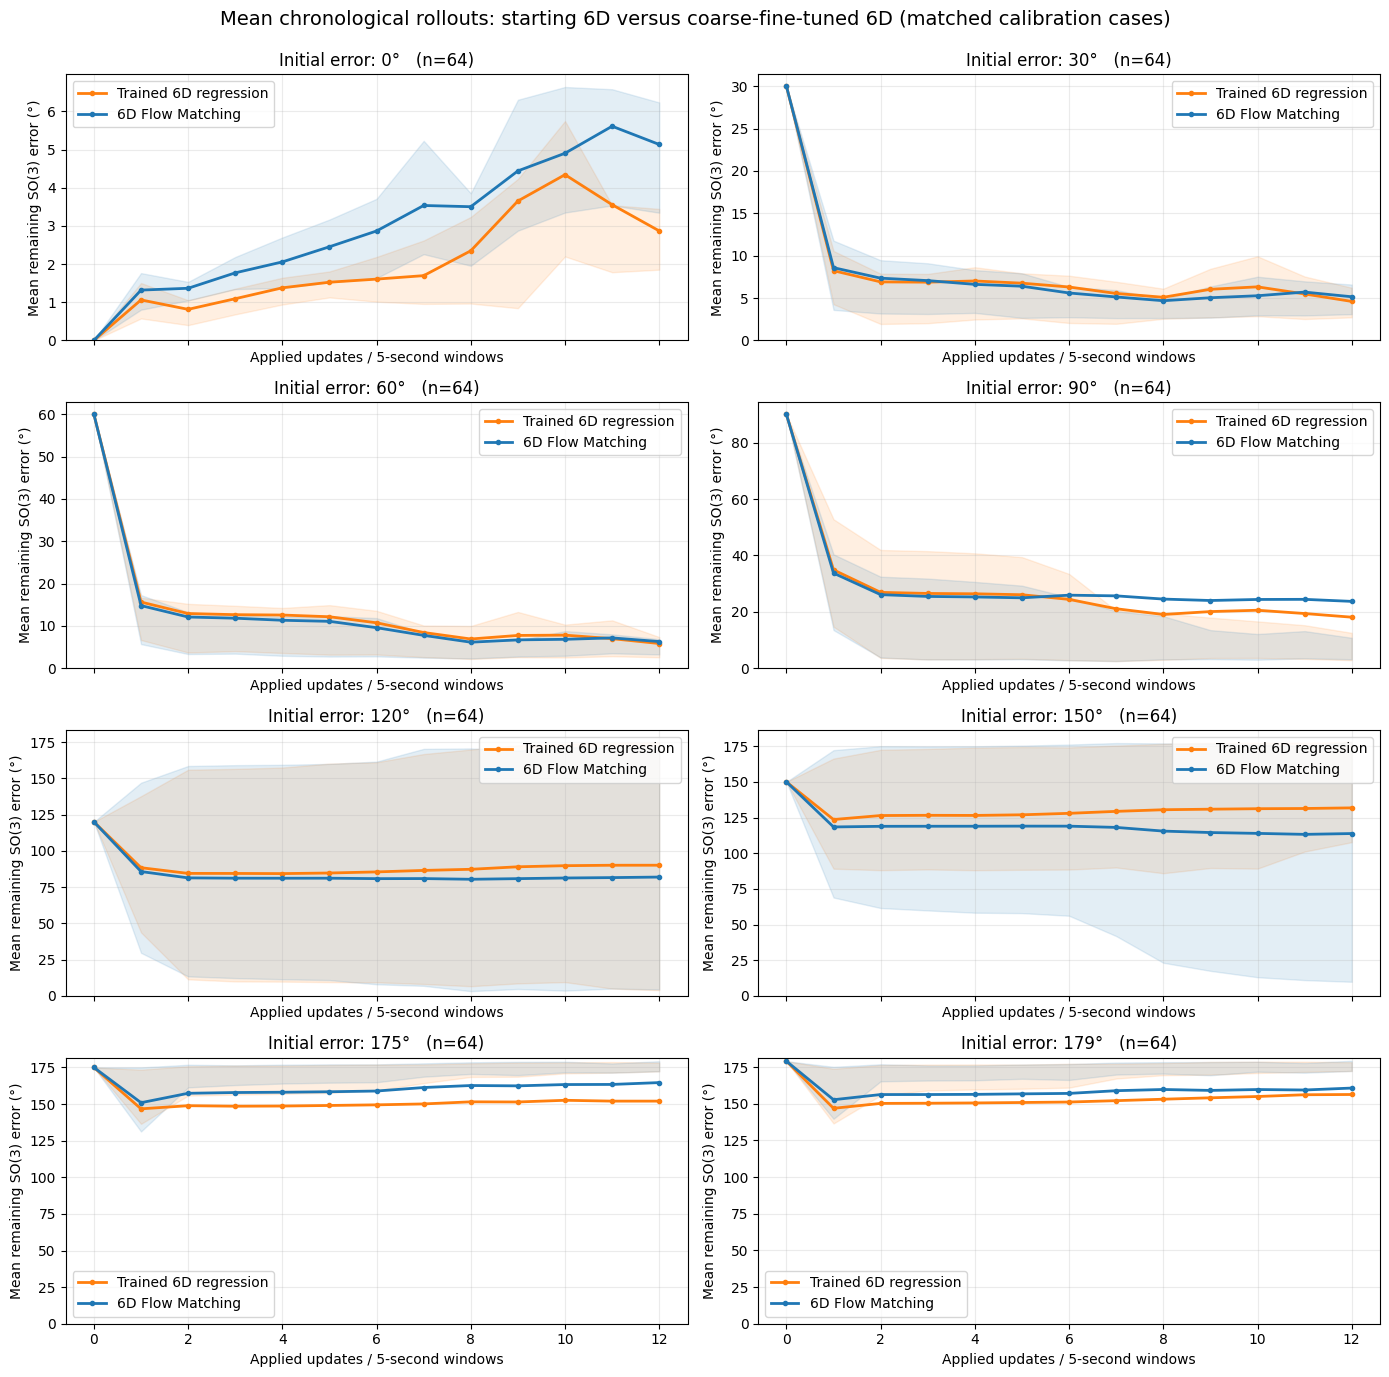

In [23]:

# Appendix B. One subplot per initial fault angle.
# Exactly two lines: trained regression and 6D FM, with optional IQR bands.

ROLL59_PLOT_COLUMNS = 2
ROLL59_SHOW_IQR = True  # Optional shaded 25–75% ranges, still only two mean curves.
ROLL59_MODEL_COLORS = {
    'Trained 6D regression': 'tab:orange',
    '6D Flow Matching': 'tab:blue',
}

roll59_num_rows = math.ceil(len(ROLL59_ANGLES_DEG) / ROLL59_PLOT_COLUMNS)

fig, axes = plt.subplots(
    roll59_num_rows,
    ROLL59_PLOT_COLUMNS,
    figsize=(14, 3.5 * roll59_num_rows),
    squeeze=False,
    sharex=True,
)

for ax, angle in zip(axes.flat, ROLL59_ANGLES_DEG):
    for model_name in ('Trained 6D regression', '6D Flow Matching'):
        curve = roll59_summary[
            (roll59_summary.angle_deg == float(angle))
            & (roll59_summary.model == model_name)
        ].sort_values('step')

        if ROLL59_SHOW_IQR:
            ax.fill_between(
                curve.step.to_numpy(),
                curve.p25_error_deg.to_numpy(),
                curve.p75_error_deg.to_numpy(),
                color=ROLL59_MODEL_COLORS[model_name],
                alpha=0.12,
            )

        ax.plot(
            curve.step,
            curve.mean_error_deg,
            marker='o',
            markersize=3,
            linewidth=2,
            color=ROLL59_MODEL_COLORS[model_name],
            label=model_name,
        )

    n_cases = int(curve.n_cases.iloc[0])

    ax.set(
        title=f'Initial error: {angle:g}°   (n={n_cases})',
        xlabel='Applied updates / 5-second windows',
        ylabel='Mean remaining SO(3) error (°)',
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(loc='best')

for ax in list(axes.flat)[len(ROLL59_ANGLES_DEG):]:
    ax.set_visible(False)

fig.suptitle(
    'Mean chronological rollouts: starting 6D versus coarse-fine-tuned 6D (matched calibration cases)',
    fontsize=14,
)

fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(ROLL59_OUTPUT_DIR / 'baseline_vs_coarse_tuned_6d_mean_by_initial_angle.png', dpi=180)

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
